In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
df = pd.read_csv(r'C:\Users\mayan\Downloads\PRCP-1003-CustTransPred\Data\train(1).csv')

In [9]:
df.head()

,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,...,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
0,train_0,0,8.9255,-6.7863,11.9081,5.0930,11.4607,-9.2834,5.1187,18.6266,...,4.4354,3.9642,3.1364,1.6910,18.5227,-2.3978,7.8784,8.5635,12.7803,-1.0914
1,train_1,0,11.5006,-4.1473,13.8588,5.3890,12.3622,7.0433,5.6208,16.5338,...,7.6421,7.7214,2.5837,10.9516,15.4305,2.0339,8.1267,8.7889,18.3560,1.9518
2,train_2,0,8.6093,-2.7457,12.0805,7.8928,10.5825,-9.0837,6.9427,14.6155,...,2.9057,9.7905,1.6704,1.6858,21.6042,3.1417,-6.5213,8.2675,14.7222,0.3965
3,train_3,0,11.0604,-2.1518,8.9522,7.1957,12.5846,-1.8361,5.8428,14.9250,...,4.4666,4.7433,0.7178,1.4214,23.0347,-1.2706,-2.9275,10.2922,17.9697,-8.9996
4,train_4,0,9.8369,-1.4834,12.8746,6.6375,12.2772,2.4486,5.9405,19.2514,...,-1.4905,9.5214,-0.1508,9.1942,13.2876,-1.5121,3.9267,9.5031,17.9974,-8.8104


In [10]:
df.columns

Index(['ID_code', 'target', 'var_0', 'var_1', 'var_2', 'var_3', 'var_4',
       'var_5', 'var_6', 'var_7',
       ...
       'var_190', 'var_191', 'var_192', 'var_193', 'var_194', 'var_195',
       'var_196', 'var_197', 'var_198', 'var_199'],
      dtype='str', length=202)

In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Columns: 202 entries, ID_code to var_199
dtypes: float64(200), int64(1), str(1)
memory usage: 310.4 MB


In [14]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
target,200000.0,0.100490,0.300653,0.0000,0.000000,0.00000,0.000000,1.0000
var_0,200000.0,10.679914,3.040051,0.4084,8.453850,10.52475,12.758200,20.3150
var_1,200000.0,-1.627622,4.050044,-15.0434,-4.740025,-1.60805,1.358625,10.3768
var_2,200000.0,10.715192,2.640894,2.1171,8.722475,10.58000,12.516700,19.3530
var_3,200000.0,6.796529,2.043319,-0.0402,5.254075,6.82500,8.324100,13.1883
...,...,...,...,...,...,...,...,...
var_195,200000.0,-0.142088,1.429372,-5.2610,-1.170700,-0.17270,0.829600,4.2729
var_196,200000.0,2.303335,5.454369,-14.2096,-1.946925,2.40890,6.556725,18.3215
var_197,200000.0,8.908158,0.921625,5.9606,8.252800,8.88820,9.593300,12.0004
var_198,200000.0,15.870720,3.010945,6.2993,13.829700,15.93405,18.064725,26.0791


In [18]:
# FIND MISSING VALUES
# EXPLORE NUMERICAL VARIABLES
# EXPLORE ABOUT CATEGORICAL VARIABLES
# FINDING RELATIONSHIPS  BETWEEN  FEATURES

In [24]:
missing_values = df.isnull().sum()

In [25]:
missing_values = missing_values[missing_values > 0].sort_values(ascending=False)

In [27]:
print("Columns with missing values:\n", missing_values)

Columns with missing values:
 Series([], dtype: int64)


In [28]:
# Check how many 0s and 1s are in the target column
print("Class counts:")
print(df['target'].value_counts())

print("\nPercentage breakdown:")
print(df['target'].value_counts(normalize=True) * 100)


Class counts:
target
0    179902
1     20098
Name: count, dtype: int64

Percentage breakdown:
target
0    89.951
1    10.049
Name: proportion, dtype: float64


Skewness values:
var_0    0.235639
var_1    0.053115
var_2    0.260313
var_3   -0.003548
dtype: float64


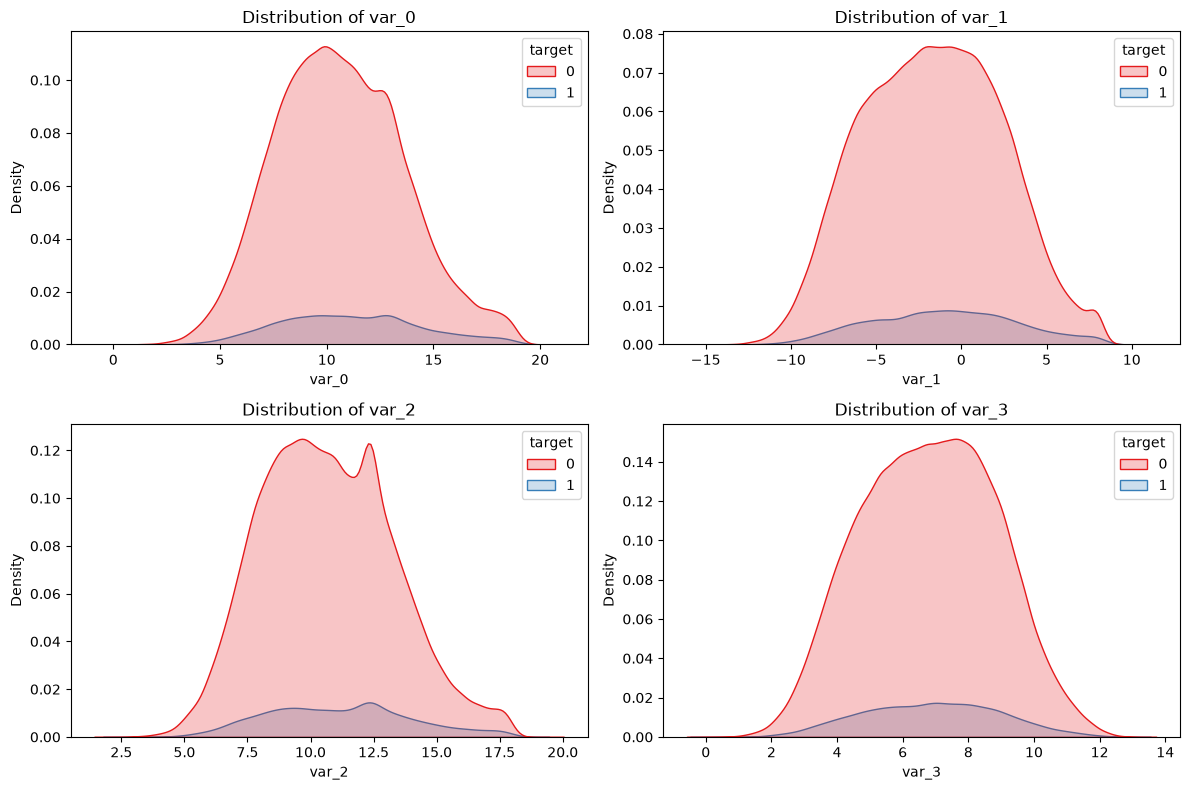

In [34]:
# 1. Check skewness values (Values between -0.5 and 0.5 mean highly symmetrical)
print("Skewness values:")
print(df[['var_0', 'var_1', 'var_2', 'var_3']].skew())

# 2. Plot the distributions
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
features = ['var_0', 'var_1', 'var_2', 'var_3']

for i, col in enumerate(features):
    ax = axes[i//2, i%2]
    sns.kdeplot(data=df, x=col, hue='target', fill=True, ax=ax, palette='Set1')
    ax.set_title(f'Distribution of {col}')

plt.tight_layout()
plt.show()


In [36]:
from sklearn.model_selection import train_test_split

X = df.drop(columns = ['ID_code' , 'target'])
y = df['target']

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training features shape: {X_train.shape}")
print(f"Validation features shape: {X_valid.shape}")

Training features shape: (160000, 200)
Validation features shape: (40000, 200)
